# Classificação de Fake News — Fake.br (`pre-processed.csv`)
**Aluna:** Letícia Rocha de Oliveira Rodrigues Pereira  |  **RU:** 4683258

Passos: 1 Aquisição → 2 Estruturação → 3 Pré-processamento → 4 Mineração (TF-IDF + bigramas) → 5 Modelagem → 6 Representação (WordCloud) → 7 Refinamento → 8 Relatório.

In [1]:
# >>> PREENCHENDO O RU AQUI - aparece nas imagens das nuvens de palavras
RU = "4683258"

## Carregando arquivos `pre-processed.csv`, de imagens e de funções auxiliares
Versão em Python puro (funciona no Windows, Linux e Google Colab), equivalente ao `wget` + `git clone` do roteiro. Baixa o CSV, o `funcoes_auxiliares.py` e as máscaras das nuvens.

In [2]:
%pip install -q matplotlib wordcloud nltk scikit-learn pandas numpy pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, urllib.request

RAW_CORPUS = 'https://raw.githubusercontent.com/roneysco/Fake.br-Corpus/master/preprocessed/pre-processed.csv'
RAW_NLP    = 'https://raw.githubusercontent.com/N-CPUninter/NLP/main/'

def baixar(url, destino):
    os.makedirs(os.path.dirname(destino) or '.', exist_ok=True)
    if not os.path.exists(destino):
        urllib.request.urlretrieve(url, destino)
        print('baixado:', destino)

baixar(RAW_CORPUS, 'pre-processed.csv')
baixar(RAW_NLP + 'funcoes_auxiliares.py', 'funcoes_auxiliares.py')
for img in ['cloud_mask.png', 'mapa_brasil_mask.png', 'thumbs_up_mask.png', 'thumbs_down_mask.png']:
    baixar(RAW_NLP + 'data/img/' + img, os.path.join('data', 'img', img))

baixado: pre-processed.csv
baixado: funcoes_auxiliares.py
baixado: data\img\cloud_mask.png
baixado: data\img\mapa_brasil_mask.png
baixado: data\img\thumbs_up_mask.png
baixado: data\img\thumbs_down_mask.png


## Importação das bibliotecas

In [4]:
import re, unicodedata
from functools import lru_cache
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import RSLPStemmer
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

from funcoes_auxiliares import gerar_nuvem_palavras

for pkg in ['punkt', 'punkt_tab', 'stopwords', 'rslp']:
    nltk.download(pkg, quiet=True)

## Criar dataframe do CSV (`read_csv`, UTF-8)

In [5]:
df = pd.read_csv('pre-processed.csv', encoding='utf-8')
df['label'] = df.label.map({'fake': 'FAKE', 'true': 'REAL'})
print(df.shape, '| nulos:', df.preprocessed_news.isna().sum())
print(df.label.value_counts().to_dict())
df.head(3)

(7200, 3) | nulos: 0
{'FAKE': 3600, 'REAL': 3600}


,index,label,preprocessed_news
0,0,FAKE,katia abreu diz vai colocar expulsao moldura n...
1,1,FAKE,ray peita bolsonaro conservador fake entrevist...
2,2,FAKE,reinaldo azevedo desmascarado policia federal ...


# PRÁTICA 1 — Modelo de classificação supervisionado para análise de Fake News

### 1. Limpeza dos textos
1.1 Tokenizar · 1.2 Retirar acentos e números · 1.3 Minúsculas · 1.4 Stopwords e pontuações · 1.5 Stemming (RSLP) · 1.6 Truncamento dos pares de notícias (normaliza nº de palavras) · 1.7 Remontar as notícias em string e criar coluna no DataFrame.

In [6]:
stop = set(stopwords.words('portuguese'))
stemmer = RSLPStemmer()

def sem_acento(s):
    return unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode()

stop_norm = {sem_acento(w) for w in stop}

@lru_cache(maxsize=None)
def radical(w):
    return stemmer.stem(w)

def tokenizar_e_limpar(texto):
    texto = sem_acento(str(texto).lower())            # 1.3 minúsculas + 1.2 acentos
    texto = re.sub(r'[^a-z\s]', ' ', texto)            # 1.2 números / 1.4 pontuações e símbolos
    tokens = word_tokenize(texto, language='portuguese')  # 1.1 tokenizar
    tokens = [t for t in tokens if t not in stop_norm and len(t) > 2]  # 1.4 stopwords
    return [radical(t) for t in tokens]                # 1.5 stemming

df['tokens'] = df.preprocessed_news.fillna('').apply(tokenizar_e_limpar)
df['n_tokens'] = df.tokens.str.len()
print('Antes do truncamento:'); print(df.groupby('label').n_tokens.agg(['count', 'sum', 'mean']))

Antes do truncamento:
       count      sum        mean
label                            
FAKE    3600   364936  101.371111
REAL    3600  2122915  589.698611


In [7]:
# 1.6 Truncamento dos pares: a notícia FAKE i (índice i) corresponde à REAL i+3600.
fake = df[df.label == 'FAKE'].sort_values('index').tokens.tolist()
real = df[df.label == 'REAL'].sort_values('index').tokens.tolist()

linhas = []
for tf, tr in zip(fake, real):
    n = min(len(tf), len(tr))
    linhas.append((' '.join(tf[:n]), 'FAKE'))     # 1.7 remontar em string
    linhas.append((' '.join(tr[:n]), 'REAL'))

df_final = pd.DataFrame(linhas, columns=['texto_preprocessado', 'label'])
df_final['y'] = (df_final.label == 'FAKE').astype(int)       # 1 = FAKE, 0 = REAL
df_final['n_palavras'] = df_final.texto_preprocessado.str.split().str.len()
print('Depois do truncamento:'); print(df_final.groupby('label').n_palavras.agg(['count', 'sum', 'mean']))
df_final.head(3)

Depois do truncamento:
       count     sum   mean
label                      
FAKE    3600  359028  99.73
REAL    3600  359028  99.73


,texto_preprocessado,label,y,n_palavras
0,kat abr diz vai coloc expulsa mold reclam sen ...,FAKE,1,82
1,pod decid expuls deput feder carl gaguim part ...,REAL,0,82
2,ray peit bolsonar conserv fak entrev danil gen...,FAKE,1,135


### 2. Matriz de frequências TF-IDF com n-gramas de 1 a 3 palavras
### 3. `train_test_split`: 75% treino / 25% teste (`random_state=42`, estratificado)

In [8]:
X_tr, X_te, y_tr, y_te = train_test_split(
    df_final.texto_preprocessado, df_final.y,
    test_size=0.25, random_state=42, stratify=df_final.y)
print('Treino:', len(X_tr), '| Teste:', len(X_te))
print('Treino por classe:', y_tr.value_counts().to_dict(), '| Teste por classe:', y_te.value_counts().to_dict())

tfidf = TfidfVectorizer(ngram_range=(1, 3), min_df=2, max_df=0.9, sublinear_tf=True)
Xtr = tfidf.fit_transform(X_tr)       # vocabulário aprendido só no treino
Xte = tfidf.transform(X_te)
print('Matriz TF-IDF de treino:', Xtr.shape)

Treino: 5400 | Teste: 1800
Treino por classe: {1: 2700, 0: 2700} | Teste por classe: {1: 900, 0: 900}
Matriz TF-IDF de treino: (5400, 92920)


### 4. Regressão logística (`solver='lbfgs'`)

In [9]:
modelo = LogisticRegression(solver='lbfgs', C=10, max_iter=2000)
modelo.fit(Xtr, y_tr)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

### 5. Predição com `predict_proba` e 6. Acurácia com `accuracy_score`

In [10]:
proba = modelo.predict_proba(Xte)            # colunas: [P(REAL), P(FAKE)]
print('Primeiras probabilidades [REAL, FAKE]:'); print(np.round(proba[:5], 3))

y_pred = np.argmax(proba, axis=1)            # classe com maior probabilidade
acc = accuracy_score(y_te, y_pred)
print(f'\nACURÁCIA NO CONJUNTO DE TESTE: {acc*100:.2f}%   (mínimo exigido: 85%)')
print(classification_report(y_te, y_pred, target_names=['REAL', 'FAKE']))

Primeiras probabilidades [REAL, FAKE]:
[[0.405 0.595]
 [0.746 0.254]
 [0.052 0.948]
 [0.753 0.247]
 [0.976 0.024]]

ACURÁCIA NO CONJUNTO DE TESTE: 90.44%   (mínimo exigido: 85%)
              precision    recall  f1-score   support

        REAL       0.90      0.91      0.90       900
        FAKE       0.91      0.90      0.90       900

    accuracy                           0.90      1800
   macro avg       0.90      0.90      0.90      1800
weighted avg       0.90      0.90      0.90      1800



## QUESTÃO 01 — Nuvem de palavras dos textos VERDADEIROS
1. Dados de treino → dicionário de tokens e frequências · 2. Separar verdadeiros e falsos · 3. `gerar_nuvem_palavras(dicionário, máscara)`.

   * Um total de 120 tokens foram computadas a partir do conjunto de dados.



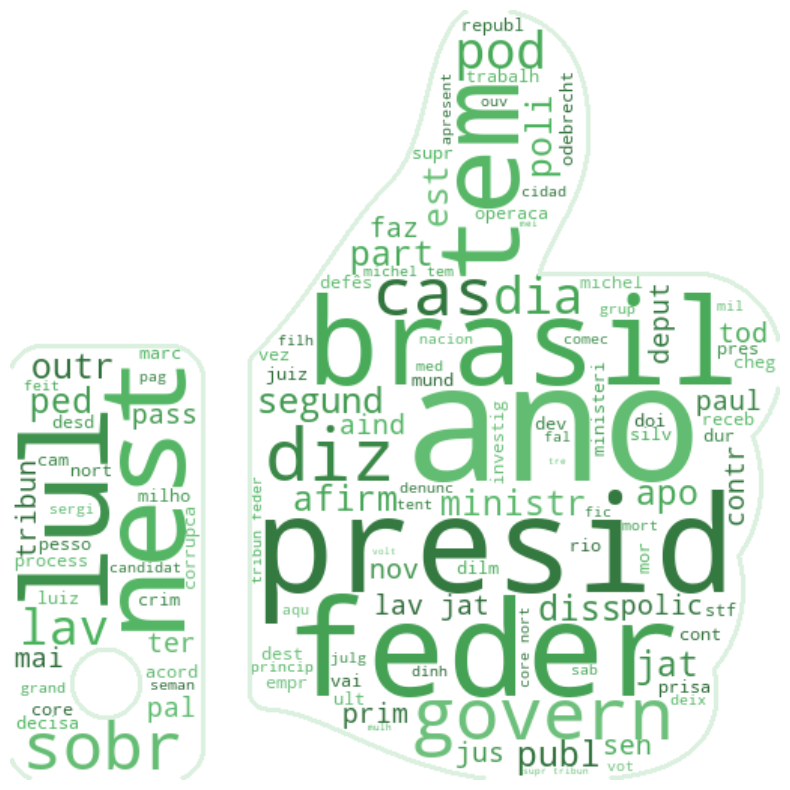

imagem salva: nuvem_real_4683258.png


In [11]:
def dicionario_frequencias(textos, top=120):
    cv = CountVectorizer(ngram_range=(1, 2), max_features=top)
    bow = cv.fit_transform(textos)
    soma = np.asarray(bow.sum(axis=0)).ravel()
    return {tok: int(f) for tok, f in zip(cv.get_feature_names_out(), soma)}

def nuvem_com_ru(dic, mascara, rotulo, arquivo):
    nuvem, _ = gerar_nuvem_palavras(dicionario_tokens_e_frequencia=dic, arquivo_mascara=mascara)
    plt.figure(figsize=(9, 9))
    plt.imshow(nuvem, interpolation='bilinear'); plt.axis('off')
    plt.title(f'{rotulo} — RU {RU}', fontsize=16)
    plt.savefig(arquivo, dpi=150, bbox_inches='tight'); plt.close()
    print('imagem salva:', arquivo)

treino = pd.DataFrame({'texto': X_tr, 'y': y_tr})
dic_real = dicionario_frequencias(treino[treino.y == 0].texto)
dic_fake = dicionario_frequencias(treino[treino.y == 1].texto)
nuvem_com_ru(dic_real, 'thumbs_up_mask.png', 'Textos VERDADEIROS', f'nuvem_real_{RU}.png')

## QUESTÃO 02 — Nuvem de palavras dos textos FALSOS

   * Um total de 120 tokens foram computadas a partir do conjunto de dados.



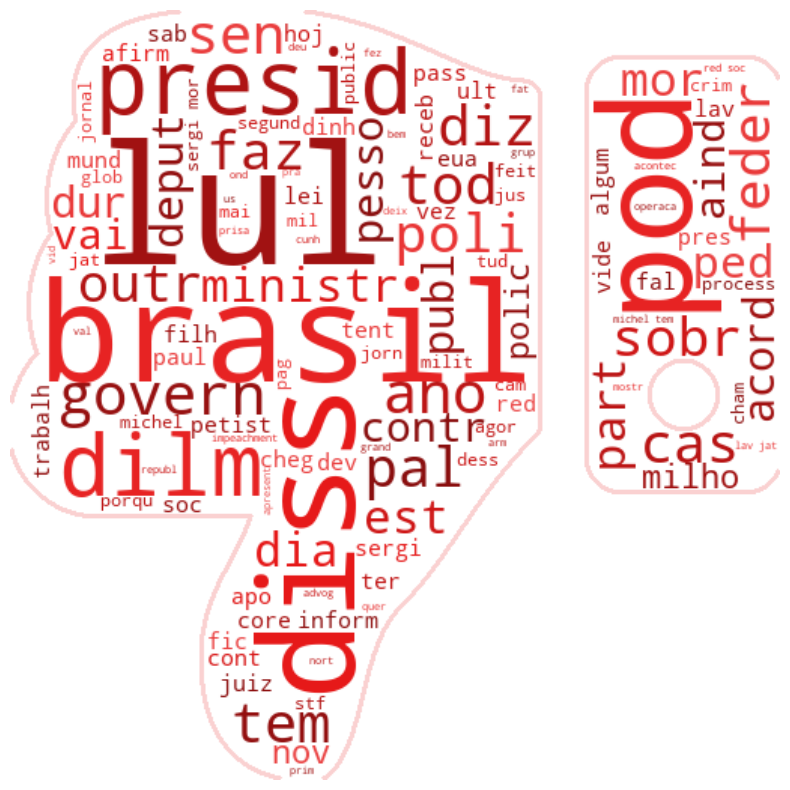

imagem salva: nuvem_fake_4683258.png


In [12]:
nuvem_com_ru(dic_fake, 'thumbs_down_mask.png', 'Textos FALSOS', f'nuvem_fake_{RU}.png')

## Relatório
**Metodologia.** Corpus Fake.br (`pre-processed.csv`, 3.600 FAKE + 3.600 REAL) carregado em DataFrame (UTF-8). Cada texto foi tokenizado, convertido para minúsculas, sem acentos, números, pontuação e stopwords (NLTK) e reduzido ao radical (RSLP). Cada notícia REAL foi truncada ao nº de palavras da FAKE pareada, igualando o total de palavras das classes. Divisão 75%/25% estratificada (`random_state=42`). TF-IDF com 1–3 gramas e regressão logística (`lbfgs`); predição com `predict_proba` e acurácia com `accuracy_score`.

**Resultado.** Ver acurácia impressa na seção 5 (mínimo exigido: 85%).

**Observação.** A normalização do tamanho dos textos evita acurácias artificialmente altas (>93%) causadas pela diferença de comprimento entre FAKE e REAL.